In [2]:
from langgraph.graph import StateGraph, START, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langchain_ollama import ChatOllama
from langchain.messages import RemoveMessage
from dotenv import load_dotenv

In [3]:
load_dotenv()

True

In [4]:
model = ChatOllama(model="llama3.2")

In [5]:
def chat(state: MessagesState): 
    response = model.invoke(state['messages'])
    return {"messages": [response]}

In [7]:
def delete_old_messages(state: MessagesState): 
    messages = state['messages']

    #if more than 10 messages, delete the earliest 6 
    if len(messages) > 10: 
        to_remove = messages[:6]
        return {"messages": [RemoveMessage(id=m.id) for m in to_remove]}
    return {}

In [8]:
builder = StateGraph(MessagesState)
builder.add_node("chat", chat)
builder.add_node("cleanup", delete_old_messages)

In [9]:
builder.add_edge(START, "chat")
builder.add_edge("chat", "cleanup")
builder.add_edge("cleanup", "__end__")

In [10]:
graph = builder.compile(checkpointer=InMemorySaver())

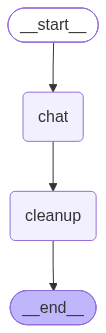

In [11]:
graph


In [12]:
config = {"configurable": {"thread_id": "t1"}}

In [13]:
#Run multip;e turns 
graph.invoke({"messages": [{"role": "user", "content": "Hi I am Milan Rai"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Tell me about LangGraph"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "Now explain checkpointer"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is langchain"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is Quantum mechnaics"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is GenAI"}]}, config)
graph.invoke({"messages": [{"role": "user", "content": "What is my name"}]}, config)

{'messages': [HumanMessage(content='What is langchain', additional_kwargs={}, response_metadata={}, id='1731d45a-5142-4126-8b62-eeef13c7ba04'),
  AIMessage(content="Langchain is an open-source, Rust-based library for building conversational AI models. It provides a set of tools and APIs for creating and training language models, as well as for fine-tuning pre-trained models for specific tasks.\n\nLangchain was designed to make it easier for developers to build conversational AI models that can understand and respond to natural language input. It provides a flexible and modular architecture that allows developers to easily integrate different components and tools to build custom models.\n\nSome of the key features and benefits of Langchain include:\n\n**Key Features:**\n\n1. **Language Model Training**: Langchain provides tools and APIs for training language models from scratch or fine-tuning pre-trained models.\n2. **Model Serving**: Langchain provides a model serving API that allows d

In [ ]:
snap = graph.get_state(config)
print("Stored messages after cleanup:", len(snap.values['messages']))